# Prédiction de prix de airbnb

But : Prédire le logarithme du prix du airbnb à partir d'un ensemble d'informations brut sur le logement

In [28]:
import pandas as pd 
import matplotlib.pyplot as plt


In [13]:
# Chargement du fichier csv
df = pd.read_csv("airbnb_train.csv")
df.head()

,id,log_price,property_type,room_type,amenities,accommodates,bathrooms,bed_type,cancellation_policy,cleaning_fee,...,last_review,latitude,longitude,name,neighbourhood,number_of_reviews,review_scores_rating,zipcode,bedrooms,beds
0,5708593,4.317488,House,Private room,"{TV,""Wireless Internet"",Kitchen,""Free parking ...",3,1.0,Real Bed,flexible,False,...,NaN,33.782712,-118.134410,Island style Spa Studio,Long Beach,0,NaN,90804,0.0,2.0
1,14483613,4.007333,House,Private room,"{""Wireless Internet"",""Air conditioning"",Kitche...",4,2.0,Real Bed,strict,False,...,2017-09-17,40.705468,-73.909439,"Beautiful and Simple Room W/2 Beds, 25 Mins to...",Ridgewood,38,86.0,11385,1.0,2.0
2,10412649,7.090077,Apartment,Entire home/apt,"{TV,""Wireless Internet"",""Air conditioning"",Kit...",6,2.0,Real Bed,flexible,False,...,NaN,38.917537,-77.031651,2br/2ba luxury condo perfect for infant / toddler,U Street Corridor,0,NaN,20009,2.0,2.0
3,17954362,3.555348,House,Private room,"{TV,""Cable TV"",Internet,""Wireless Internet"",""A...",1,1.0,Real Bed,flexible,True,...,2017-09-29,40.736001,-73.924248,Manhattan view from Queens. Lovely single room .,Sunnyside,19,96.0,11104,1.0,1.0
4,9969781,5.480639,House,Entire home/apt,"{TV,""Cable TV"",Internet,""Wireless Internet"",Ki...",4,1.0,Real Bed,moderate,True,...,2017-08-28,37.744896,-122.430665,Zen Captured Noe Valley House,Noe Valley,15,96.0,94131,2.0,2.0


## Section 1 : Présentation des données

In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22234 entries, 0 to 22233
Data columns (total 28 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   id                      22234 non-null  int64  
 1   log_price               22234 non-null  float64
 2   property_type           22234 non-null  object 
 3   room_type               22234 non-null  object 
 4   amenities               22234 non-null  object 
 5   accommodates            22234 non-null  int64  
 6   bathrooms               22183 non-null  float64
 7   bed_type                22234 non-null  object 
 8   cancellation_policy     22234 non-null  object 
 9   cleaning_fee            22234 non-null  bool   
 10  city                    22234 non-null  object 
 11  description             22234 non-null  object 
 12  first_review            17509 non-null  object 
 13  host_has_profile_pic    22178 non-null  object 
 14  host_identity_verified  22178 non-null

In [6]:
print("\n=== Statistiques pour colonnes catégorielles ===")
df.describe(include=['object'])


=== Statistiques pour colonnes catégorielles ===


,property_type,room_type,amenities,bed_type,cancellation_policy,city,description,first_review,host_has_profile_pic,host_identity_verified,host_response_rate,host_since,instant_bookable,last_review,name,neighbourhood,zipcode
count,22234,22234,22234,22234,22234,22234,22234,17509,22178,22178,16759,22178,22234,17518,22234,20148,21931
unique,31,3,21160,5,5,6,22169,2096,2,2,70,2852,2,1042,22155,558,674
top,Apartment,Entire home/apt,{},Real Bed,strict,NYC,Welcome to our unique shared space. This commu...,2017-01-01,t,t,100%,2015-03-30,f,2017-04-30,East Village Studio,Williamsburg,11211.0
freq,14635,12348,161,21622,9726,9739,3,88,22108,14953,13048,68,16401,420,4,878,425


In [8]:
df.dtypes

id                          int64
log_price                 float64
property_type              object
room_type                  object
amenities                  object
accommodates                int64
bathrooms                 float64
bed_type                   object
cancellation_policy        object
cleaning_fee                 bool
city                       object
description                object
first_review               object
host_has_profile_pic       object
host_identity_verified     object
host_response_rate         object
host_since                 object
instant_bookable           object
last_review                object
latitude                  float64
longitude                 float64
name                       object
neighbourhood              object
number_of_reviews           int64
review_scores_rating      float64
zipcode                    object
bedrooms                  float64
beds                      float64
dtype: object

In [11]:
print("\n=== Nombre de valeurs nulles ===")
df.isnull().sum()


=== Nombre de valeurs nulles ===


id                           0
log_price                    0
property_type                0
room_type                    0
amenities                    0
accommodates                 0
bathrooms                   51
bed_type                     0
cancellation_policy          0
cleaning_fee                 0
city                         0
description                  0
first_review              4725
host_has_profile_pic        56
host_identity_verified      56
host_response_rate        5475
host_since                  56
instant_bookable             0
last_review               4716
latitude                     0
longitude                    0
name                         0
neighbourhood             2086
number_of_reviews            0
review_scores_rating      4978
zipcode                    303
bedrooms                    26
beds                        35
dtype: int64

In [ ]:
print("\n=== Matrice de corrélation ===")
df.corr(numeric_only=True)


=== Matrice de corrélation ===


,id,log_price,accommodates,bathrooms,cleaning_fee,latitude,longitude,number_of_reviews,review_scores_rating,bedrooms,beds
id,1.000000,-0.002122,0.002561,0.001967,0.007374,-0.004771,-0.005605,-0.003930,-0.003745,0.003300,0.002608
log_price,-0.002122,1.000000,0.564874,0.369118,0.115116,0.005231,-0.045348,-0.039138,0.092342,0.472871,0.435212
accommodates,0.002561,0.564874,1.000000,0.515996,0.186395,-0.067332,-0.080826,0.046678,-0.020023,0.713512,0.817505
bathrooms,0.001967,0.369118,0.515996,1.000000,0.049494,-0.124475,-0.126350,-0.044520,0.007077,0.603252,0.536272
cleaning_fee,0.007374,0.115116,0.186395,0.049494,1.000000,-0.045026,-0.051351,0.117062,0.028606,0.107559,0.133137
latitude,-0.004771,0.005231,-0.067332,-0.124475,-0.045026,1.000000,0.895423,-0.014064,-0.024738,-0.052549,-0.069950
longitude,-0.005605,-0.045348,-0.080826,-0.126350,-0.051351,0.895423,1.000000,-0.044119,-0.037644,-0.076086,-0.076922
number_of_reviews,-0.003930,-0.039138,0.046678,-0.044520,0.117062,-0.014064,-0.044119,1.000000,0.005848,-0.036074,0.031078
review_scores_rating,-0.003745,0.092342,-0.020023,0.007077,0.028606,-0.024738,-0.037644,0.005848,1.000000,0.016073,-0.025039
bedrooms,0.003300,0.472871,0.713512,0.603252,0.107559,-0.052549,-0.076086,-0.036074,0.016073,1.000000,0.704580


## Section 2 : Distribution de la variable cible (log_price)

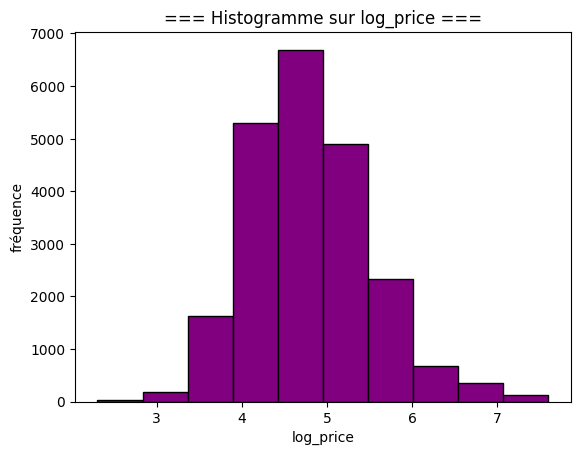

In [23]:
plt.title("=== Histogramme sur log_price ===")
plt.hist(df["log_price"],bins=10,color="purple",edgecolor="black")
plt.xlabel("log_price")
plt.ylabel("fréquence")
plt.show()

## Section 3 : Exploration des variables catégorielles

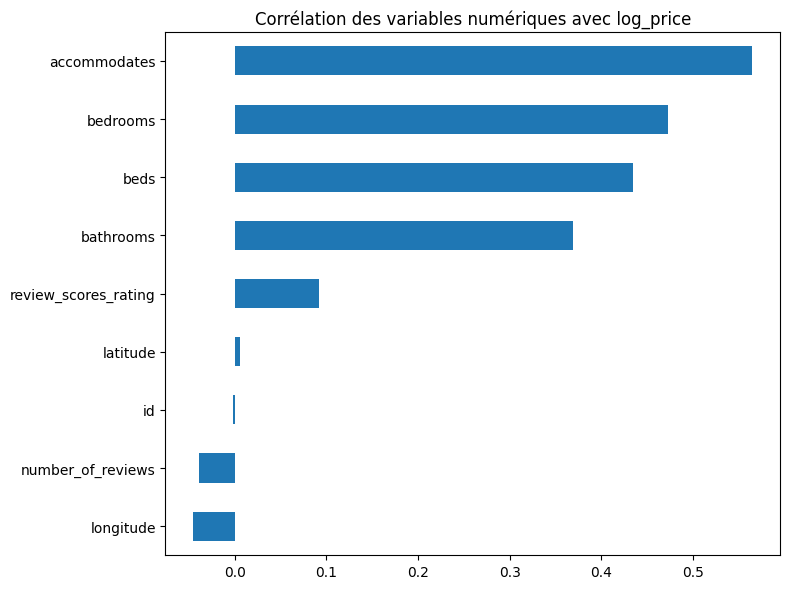

In [27]:
# Sélectionner uniquement les colonnes numériques
numeric_cols = df.select_dtypes(include=['number']).columns

corr = df[numeric_cols].corr()['log_price'].drop('log_price').sort_values()
corr.plot(kind='barh', figsize=(8, 6))
plt.title('Corrélation des variables numériques avec log_price')
plt.tight_layout()
plt.show()

## Observations
- Les variables de capacité (`accommodates`, `bedrooms`, `beds`, `bathrooms`) sont 
  fortement corrélées avec `log_price` : plus le logement est grand, plus il est cher.
- `latitude`/`longitude` ont une corrélation linéaire quasi nulle, mais on les conserve
  car des modèles non-linéaires (Random Forest) peuvent détecter des effets de zone.
- `id` est un identifiant sans valeur prédictive : on le supprime.

## L'idée
`accommodates`, `bedrooms`, `beds`, `bathrooms` sont toutes fortement corrélées entre elles et avec `log_price`. Un grand appartement a tendance à avoir beaucoup de chambres, beaucoup de lits, beaucoup de salles de bain... Ces 4 colonnes portent en grande partie la même information : "la taille du logement".
L'ACP va justement détecter ça et créer une nouvelle colonne, qu'on appellera composante principale, résumant ces 4 variables en 1 seule, tout en gardant le maximum d'information.